In [41]:
import os
from typing import List
from pydantic import BaseModel
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from langchain_classic.schema import Document
from langchain_community.vectorstores import FAISS
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders.youtube import YoutubeLoader
from langchain_community.document_loaders import ArxivLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.tools import WikipediaQueryRun
from langchain_classic.utilities import WikipediaAPIWrapper
from langgraph.graph import StateGraph, END

In [3]:
!ollama pull deepseek-v2

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕██████████████████▏   32 B                         
pulling 2b2c35718a16: 100% ▕██████████████████▏  494 B                         
verifying sha256 digest 
writing manifest ⠋ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕█████

In [6]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
load_dotenv()
os.environ["OLLAMA_API_KEY"]=os.getenv("OLLAMA_API_KEY")
llm=init_chat_model(
    "deepseek-v2",
    model_provider="ollama",
    temperature=0.1
)
llm.invoke("Hello , can you tell me about yourself").content

" Hello! I'm an AI language model designed to assist with a wide range of tasks, from answering questions to generating text based on the input I receive. My goal is to provide helpful, accurate, and relevant information to users like you. I'm constantly learning and improving, so I can adapt to different topics and contexts. If you have any questions or need assistance, feel free to ask!"

In [7]:
from langchain_huggingface import HuggingFaceEmbeddings

In [53]:
## Tool Creation:
def load_text_retriever(file_path):
    docs = TextLoader(file_path, encoding="utf-8").load()
    splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
    chunks = splitter.split_documents(docs)
    vs = FAISS.from_documents(chunks, HuggingFaceEmbeddings())
    return vs.as_retriever()

def load_youtube_retriever():
    # Mocked YouTube transcript text
    content = """
    This video explains how agentic AI systems rely on feedback loops, memory, and tool use.
    It compares them to traditional pipeline-based LLMs. Temporal reasoning and autonomous tasking are emphasized.
    """
    doc = Document(page_content=content, metadata={"source": "youtube"})
    vectorstore = FAISS.from_documents([doc], HuggingFaceEmbeddings())
    return vectorstore.as_retriever()



wiki_tool = WikipediaQueryRun(
    api_wrapper=WikipediaAPIWrapper()
)

def wikipedia_search(query: str) -> str:
    print("🌐 Searching Wikipedia...")
    return wiki_tool.invoke({"query": query})


    

In [54]:
text_retriever=load_text_retriever("sample_docs.txt")
youtube_retriever=load_youtube_retriever()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 798.21it/s]


In [55]:
# State:
class MultiSourceRAGState(BaseModel):
    question: str
    text_docs: List[Document] = []
    yt_docs: List[Document] = []
    wiki_context: str = ""
    arxiv_context: str = ""
    final_answer: str = ""

In [56]:

## Retrieval Nodes:
def retrieve_text(state: MultiSourceRAGState) -> MultiSourceRAGState:
    docs = text_retriever.invoke(state.question)
    return state.model_copy(update={"text_docs": docs})

def retrieve_yt(state: MultiSourceRAGState) -> MultiSourceRAGState:
    docs = youtube_retriever.invoke(state.question)
    return state.model_copy(update={"yt_docs": docs})

def retrieve_wikipedia(state: MultiSourceRAGState) -> MultiSourceRAGState:
    print("🌐 Retrieving information from Wikipedia...")

    result = wikipedia_search(state.question)

    return state.model_copy(
        update={
            "wiki_context": result
        }
    )

In [57]:
# Synthesize:
def synthesize_answer(state: MultiSourceRAGState) -> MultiSourceRAGState:
    
    context = ""

    context += "\n\n[Internal Docs]\n" + "\n".join([doc.page_content for doc in state.text_docs])
    context += "\n\n[YouTube Transcript]\n" + "\n".join([doc.page_content for doc in state.yt_docs])
    context += "\n\n[Wikipedia]\n" + state.wiki_context
    

    prompt = f"""You have retrieved relevant context from multiple sources. Now synthesize a complete and coherent answer.

Question: {state.question}

Context:
{context}

Final Answer:"""

    answer = llm.invoke(prompt).content.strip()
    return state.model_copy(update={"final_answer": answer})

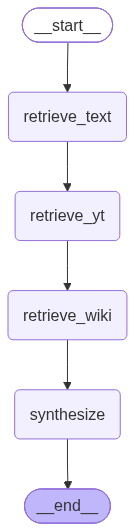

In [58]:
builder = StateGraph(MultiSourceRAGState)

builder.add_node("retrieve_text", retrieve_text)
builder.add_node("retrieve_yt", retrieve_yt)
builder.add_node("retrieve_wiki", retrieve_wikipedia)

builder.add_node("synthesize", synthesize_answer)

builder.set_entry_point("retrieve_text")
builder.add_edge("retrieve_text", "retrieve_yt")
builder.add_edge("retrieve_yt", "retrieve_wiki")

builder.add_edge("retrieve_wiki", "synthesize")
builder.add_edge("synthesize", END)

graph = builder.compile()
graph

In [59]:
question = "What are transformer agents and how are they evolving in recent research?"
state = MultiSourceRAGState(question=question)
result = graph.invoke(state)

print("✅ Final Answer:\n")
print(result["final_answer"])


🌐 Retrieving information from Wikipedia...
🌐 Searching Wikipedia...
✅ Final Answer:

Transformer agents are a type of artificial intelligence model that leverage the transformer architecture, which is known for its ability to handle sequential data and process it in parallel. These agents are designed to be highly adaptable and capable of executing complex tasks by learning from their environment and adjusting their approach based on new observations. They are part of a broader trend in AI research and development, particularly in the field of generative AI, which has seen significant advancements in recent years.

In recent research, transformer agents are evolving in several ways:

1. **Enhanced Learning Capabilities**: Transformer agents are being fine-tuned to better understand context and adapt to new information, which is crucial for tasks that require complex reasoning and decision-making.

2. **Integration with Tools**: The ability to interact with external tools and services h

In [60]:
result

{'question': 'What are transformer agents and how are they evolving in recent research?',
 'text_docs': [Document(id='05837412-7bf6-4c1c-a7ef-6c508d1b8b13', metadata={'source': 'sample_docs.txt'}, page_content='- Autonomy: Agents can execute multiple steps without requiring continuous human instructions.\n- Adaptability: They can change their approach based on new observations.\n- Error Handling: They can identify failures and attempt alternative actions.\n- Complex Task Execution: They can solve problems requiring multiple operations.\n- Feedback-Based Decisions: Observations help refine decisions during task execution.\n- Tool Integration: Agents can interact with external systems and services.'),
  Document(id='ca50978e-b498-4327-9582-345fc9b7e5b3', metadata={'source': 'sample_docs.txt'}, page_content='The basic principle is:\n\nTHINK -> ACT -> OBSERVE -> EVALUATE -> REPEAT\n\nThis architecture is used in modern agentic AI workflows and frameworks such as LangGraph and LangChain.\n\